In [2]:
import numpy as np
import math
import time
from numpy.linalg import solve

# analytical solution parameters
AA = 1
aa = 2.0*np.pi
bb = 3.0*np.pi

left_boundary = 0.0
right_boundary = 8.0

lamb = 4
def u(x):
    return AA * np.sin(bb * (x + 0.05)) * np.cos(aa * (x + 0.05)) + 2.0

def d2u_dx2(x):
    return -AA*(aa*aa+bb*bb)*np.sin(bb*(x+0.05))*np.cos(aa*(x+0.05))\
           -2.0*AA*aa*bb*np.cos(bb*(x+0.05))*np.sin(aa*(x+0.05))

def f(x):
    return(d2u_dx2(x) + lamb*u(x))

vanal_u = np.vectorize(u)
vanal_f = np.vectorize(f)
##然后我们就可以直接进行线性系统的装配，并返回矩阵和向量 

# calculate the matrix A,f in linear equations system 'Au=f'
def cal_matrix(N, points):
    A = np.zeros((N+1,N+1),dtype=np.float64)
    dx = (right_boundary - left_boundary)/N
    for i in range(1,N):
        A[i,i-1] = 1/(dx**2)
        A[i,i] = lamb - 2/(dx**2)
        A[i,i+1] = 1/(dx**2)
    A[0,0] = 1.0
    A[N,N] = 1.0
    f = np.zeros((N+1,1),dtype=np.float64)
    f[0,0] = u(points[0])
    f[1:N] = vanal_f(points[1:N]).reshape((-1,1))
    f[N] = u(points[-1])
    return(A,f)

In [3]:
# calculate the matrix A,f in linear equations system 'Au=f'
def cal_matrix(N, points):
    A = np.zeros((N+1,N+1),dtype=np.float64)
    dx = (right_boundary - left_boundary)/N
    for i in range(1,N):
        A[i,i-1] = 1/(dx**2)
        A[i,i] = lamb - 2/(dx**2)
        A[i,i+1] = 1/(dx**2)
    A[0,0] = 1.0
    A[N,N] = 1.0
    f = np.zeros((N+1,1),dtype=np.float64)
    f[0,0] = u(points[0])
    f[1:N] = vanal_f(points[1:N]).reshape((-1,1))
    f[N] = u(points[-1])
    return(A,f)

***********************
N = M = 100
L_infty= 0.4038518006879608 L_2= 0.6818204170644571
***********************
N = M = 200
L_infty= 0.10009073936892454 L_2= 0.16727260903614227
***********************
N = M = 400
L_infty= 0.02486975848355799 L_2= 0.041674282365398385
***********************
N = M = 800
L_infty= 0.006221760356481809 L_2= 0.010413267706642002
***********************
N = M = 1600
L_infty= 0.0015548590705942722 L_2= 0.0026033988645023766


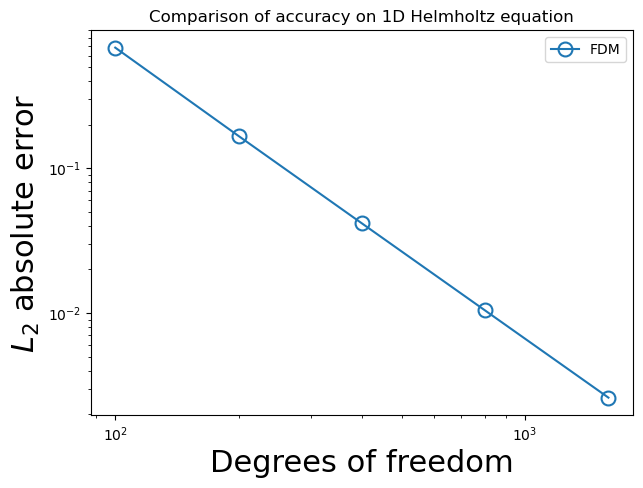

In [4]:
# calculate the l^{inf}-norm and l^{2}-norm error for u
def test(points, u):
    true_values = vanal_u(points)
    numerical_values = u
    epsilon = true_values - numerical_values
    epsilon = np.maximum(epsilon, -epsilon)
    error_inf = epsilon.max()
    error_l2 = math.sqrt(8*sum(epsilon*epsilon)/len(epsilon))
    print('L_infty=',error_inf,'L_2=',error_l2)
    return(error_l2)

def error_plot(multi_Errors):
    import matplotlib.pyplot as plt
    plt.figure(figsize=[7, 5])
    plt.tick_params(labelsize=10)
    font2 = {
    'weight' : 'normal',
    'size'   : 22,
    }
    plt.xlabel('Degrees of freedom',font2)
    plt.ylabel('$L_2$ absolute error',font2)
    plt.xscale('log')
    plt.yscale('log')
    Label = ['FDM','PINN','RFM']
    for i in range(len(multi_Errors)):
        Error = multi_Errors[i]
        plt.plot(Error[:,0], Error[:,1], \
                 lw=1.5, ls='-', clip_on=False,\
                 marker='o', markersize=10, \
                 label = Label[i],\
                 markerfacecolor='none',\
                 markeredgewidth=1.5)
    plt.legend()
    plt.title("Comparison of accuracy on 1D Helmholtz equation")
    plt.show()

def time_plot(multi_Errors):
    import matplotlib.pyplot as plt
    plt.figure(figsize=[7, 5])
    plt.tick_params(labelsize=10)
    font2 = {
    'weight' : 'normal',
    'size'   : 22,
    }
    plt.xlabel('Degrees of freedom',font2)
    plt.ylabel('Solving time',font2)
    Label = ['FDM','PINN','RFM']
    for i in range(len(multi_Errors)):
        Error = multi_Errors[i]
        plt.plot(Error[:,0], Error[:,2], \
                 lw=1.5, ls='-', clip_on=False,\
                 marker='o', markersize=10, \
                 label = Label[i],\
                 markerfacecolor='none',\
                 markeredgewidth=1.5)
    plt.legend()
    plt.title("Comparison of efficiency on 1D Helmholtz equation")
    plt.show()
    
def main(N):
    time_begin = time.time()
    points = np.linspace(0, 8.0, N+1)
    A,f = cal_matrix(N,points)
    u = solve(A,f).reshape((-1))
    error = test(points, u)
    time_end = time.time()
    return(error, time_end - time_begin)

if __name__ == '__main__':
    FDM_Error = np.zeros([5,3])
    for i in range(5):
        N = int(100 * 2**i)
        print('***********************')
        print("N = M =",N)
        FDM_Error[i,0] = N
        FDM_Error[i,1], FDM_Error[i,2] = main(N)
    
    error_plot([FDM_Error])

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.autograd import Variable
torch.set_default_dtype(torch.float64)

R_m = 1.0
def weights_init(m):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.uniform_(m.weight, a = -R_m, b = R_m)
        nn.init.uniform_(m.bias, a = -R_m, b = R_m)

# network definition
class Network(nn.Module):
    def __init__(self, d, M):
        super(Network, self).__init__()
        self.fc_layer = nn.Sequential(nn.Linear(d, M, bias=True),nn.Tanh())
        self.output_layer = nn.Linear(M, 1, bias = False)
        
    def forward(self, x):
        h = self.fc_layer(x)
        out = self.output_layer(h)
        return out

# loss definition
class Loss():
    def __init__(self, net, left_boundary, right_boundary):
        self.net = net
        self.left_boundary = left_boundary
        self.right_boundary = right_boundary

    def sample(self, N):
        x = torch.tensor(np.float64(np.linspace(self.left_boundary, self.right_boundary, N+1)[1:N]),requires_grad=True).reshape(-1,1)
        x_boundary_left = torch.ones([1],requires_grad=True) * self.left_boundary
        x_boundary_right = torch.ones([1],requires_grad=True) * self.right_boundary
        return x, x_boundary_left, x_boundary_right

    def loss_func(self, N):
        # helmholtz equation
        x, x_boundary_left, x_boundary_right = self.sample(N)
        x = Variable(x, requires_grad=True)
        y = self.net(x)
        dx = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(self.net(x)), create_graph=True)[0].reshape(-1, 1)
        dxx = torch.autograd.grad(dx, x, grad_outputs=torch.ones_like(dx), create_graph=True)[0].reshape(-1, 1)
        
        f = -AA*(aa*aa+bb*bb)*torch.sin(bb*(x+0.05))*torch.cos(aa*(x+0.05))\
           -2.0*AA*aa*bb*torch.cos(bb*(x+0.05))*torch.sin(aa*(x+0.05))\
           -lamb * (AA * torch.sin(bb * (x + 0.05)) * torch.cos(aa * (x + 0.05)) + 2.0)
        diff_error = (dxx - lamb*self.net(x) - f.reshape(-1, 1))**2
        
        # boundary condition
        bd_left_error = (self.net(x_boundary_left) - (AA * torch.sin(bb * (x_boundary_left + 0.05)) * torch.cos(aa * (x_boundary_left + 0.05)) + 2.0)) ** 2
        bd_right_error = (self.net(x_boundary_right) - (AA * torch.sin(bb * (x_boundary_right + 0.05)) * torch.cos(aa * (x_boundary_right + 0.05)) + 2.0)) ** 2
        
        return torch.mean(diff_error + bd_left_error + bd_right_error)